# Step 2: Exploratory Data Analysis (EDA)
Goal: understand distributions, spot data quality problems and form first hypotheses. Nothing is changed in this step; issues are logged for Step 3.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RAW, PROC, IMG = Path('../data/raw'), Path('../data/processed'), Path('../images')
IMG.mkdir(exist_ok=True); PROC.mkdir(parents=True, exist_ok=True)
pd.set_option('display.float_format', '{:,.2f}'.format)
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.spines.top': False, 'axes.spines.right': False})
COLOR = '#2E6F95'

def save(fname):
    plt.tight_layout(); plt.savefig(IMG / fname, dpi=120); plt.show()

def load_raw():
    # EPIC_ID is built from client names: drop it on load so it never appears in any output
    terms = pd.read_excel(RAW / '1-insurance_2025_policy_terms.xlsx', sheet_name='result').drop(columns='EPIC_ID')
    demo = pd.read_excel(RAW / '2-insurance_2025_demographics.xlsx')
    return terms, demo

In [2]:
terms, demo = load_raw()

## 2.1 Missing values

In [3]:
miss = pd.concat({'policy_terms': terms.isna().mean(), 'demographics': demo.isna().mean()}).rename('missing_share')
miss[miss > 0].to_frame().style.format('{:.1%}')

The policy terms table has no missing values. Demographics fields are 60% to 84% empty, mainly because property policies have no drivers or vehicles.

## 2.2 Target variable

In [4]:
print(terms[['CAN_REN', 'CAN_MT']].mean().map('{:.1%}'.format))
pd.crosstab(terms['Term_Status'], [terms['CAN_REN'], terms['CAN_MT']], margins=True)

CAN_REN    10.8%
CAN_MT      6.3%
dtype: str


CAN_REN          0            1     All
CAN_MT           0     1      0        
Term_Status                            
CAN              0  6283   7140   13423
INA              0     0      4       4
LAP              0     0   3684    3684
NEW          21659     0      0   21659
REI           1044     0      0    1044
REN          60182     0      4   60186
All          82885  6283  10832  100000

The cancellation flags agree with `Term_Status`: all CAN, LAP and INA terms carry a flag, and active statuses almost never do.
A few REN terms carry `CAN_REN = 1`, which is a small inconsistency to keep in mind.

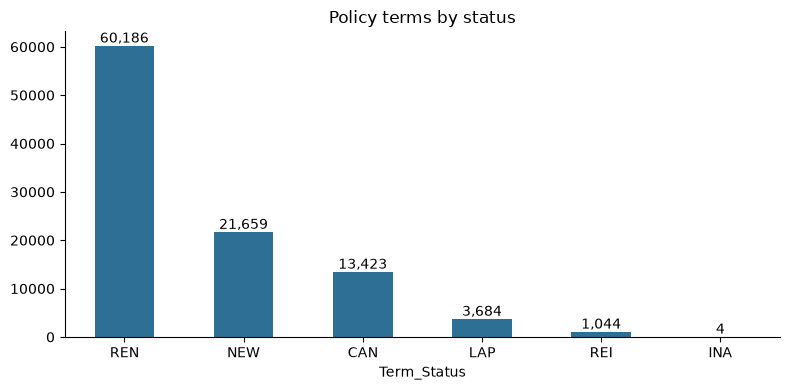

In [5]:
status = terms['Term_Status'].value_counts()
ax = status.plot.bar(color=COLOR, rot=0, title='Policy terms by status')
ax.bar_label(ax.containers[0], fmt='{:,.0f}')
save('eda_01_status.png')

## 2.3 Categorical variables

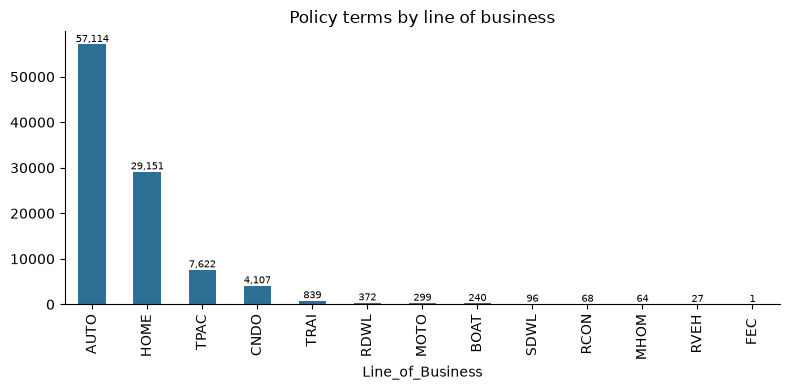

Line_of_Business,AUTO,HOME,TPAC,CNDO,TRAI,RDWL,MOTO,BOAT,SDWL,RCON,MHOM,RVEH,FEC
count,57114,29151,7622,4107,839,372,299,240,96,68,64,27,1


In [6]:
lob = terms['Line_of_Business'].value_counts()
ax = lob.plot.bar(color=COLOR, title='Policy terms by line of business'); ax.bar_label(ax.containers[0], fmt='{:,.0f}', fontsize=7)
save('eda_02_lob.png')
lob.to_frame().T

In [7]:
prov = terms['Province'].value_counts(dropna=False)
prov.to_frame().T

Province,ON,AB,NB,NS,BC,SK,NL,MB,PE,NF,,QC,NT,NU,YT,NW,MN
count,59893,27301,7319,2467,1729,341,245,236,191,155,105,6,4,3,2,2,1


**Issues found**
- Province uses two codes for the same place: NF and NL (Newfoundland), MN and MB (Manitoba), NW and NT (Northwest Territories). About 105 rows have a blank province.
- One record has line of business `FEC`, which is not in the data dictionary.
- Ontario and Alberta hold 87% of terms; very small provinces will be excluded from rate comparisons.

In [8]:
print('Raw LOB values with spaces:', [v for v in terms['Line_of_Business'].unique() if v != v.strip()])

Raw LOB values with spaces: ['FEC ']


## 2.4 Premium

In [9]:
terms['Term_Premium'].describe(percentiles=[.01, .25, .5, .75, .99, .999])

count     100,000.00
mean        2,101.25
std        14,431.05
min             0.21
1%            183.00
25%         1,042.00
50%         1,662.00
75%         2,524.00
99%         7,453.28
99.9%      13,074.01
max     2,874,713.17
Name: Term_Premium, dtype: float64

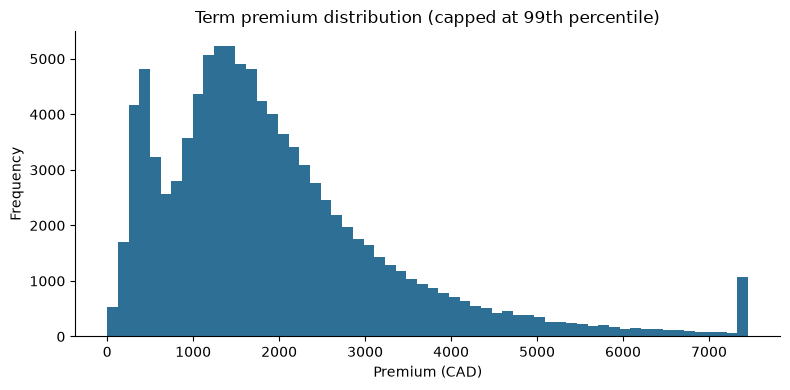

Premiums below $50: 338 | above $20,000: 35


In [10]:
ax = terms['Term_Premium'].clip(upper=terms['Term_Premium'].quantile(.99)).plot.hist(bins=60, color=COLOR)
ax.set_title('Term premium distribution (capped at 99th percentile)'); ax.set_xlabel('Premium (CAD)')
save('eda_03_premium.png')
print('Premiums below $50:', (terms['Term_Premium'] < 50).sum(), '| above $20,000:', (terms['Term_Premium'] > 20_000).sum())

Premium is right-skewed with a median of about $1,660. A handful of terms are near zero or above $20,000 (max $2.87M), which looks like data entry or commercial-size values.

## 2.5 Dates and time trend

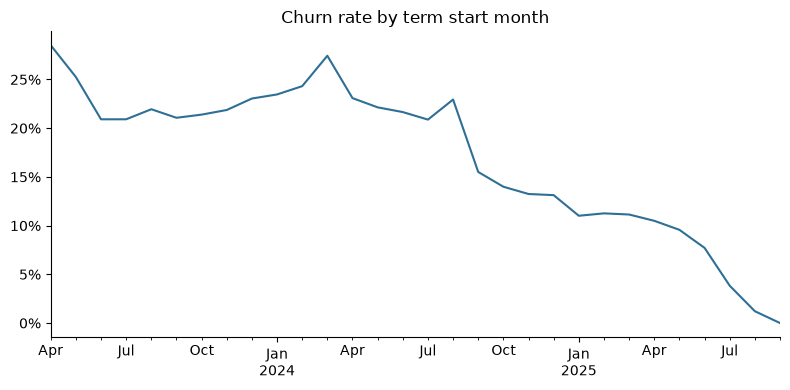

In [11]:
monthly = terms.set_index('Term_Effective_Date').resample('MS').agg({'Policy_Term_id': 'size', 'CAN_REN': 'mean', 'CAN_MT': 'mean'})
monthly = monthly[monthly['Policy_Term_id'] > 100]
fig, ax = plt.subplots()
(monthly['CAN_REN'] + monthly['CAN_MT']).plot(ax=ax, color=COLOR, title='Churn rate by term start month')
ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0%}'); ax.set_xlabel('')
save('eda_04_monthly_churn.png')

Churn drops sharply for terms that started in 2025. These terms have not reached their renewal date yet, so their renewal cancellations cannot be observed. This is a **right-censoring** effect and is noted as a limitation.

In [12]:
date_issues = pd.Series({
    'Expiration before effective date': (terms['Term_Expiration_Date'] < terms['Term_Effective_Date']).sum(),
    'Client first written after term start': (terms['Client_First_Written'] > terms['Term_Effective_Date']).sum(),
})
date_issues.to_frame('rows')

,rows
Expiration before effective date,0
Client first written after term start,3


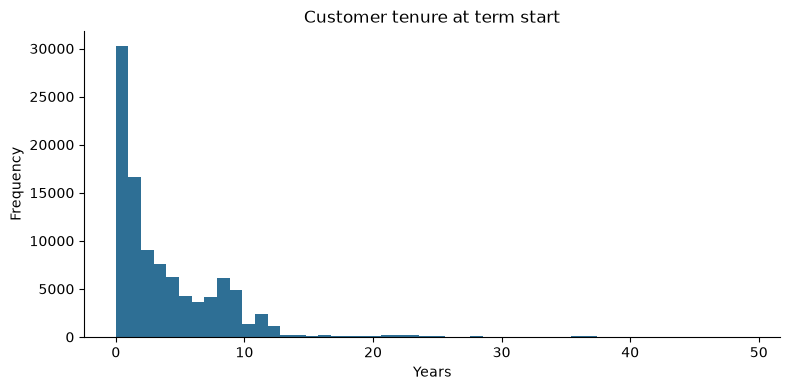

count   100,000.00
mean          3.53
std           4.45
min          -0.00
25%           0.00
50%           2.00
75%           6.00
max          49.19
dtype: float64

In [13]:
tenure = (terms['Term_Effective_Date'] - terms['Client_First_Written']).dt.days / 365.25
ax = tenure.plot.hist(bins=50, color=COLOR, title='Customer tenure at term start'); ax.set_xlabel('Years')
save('eda_05_tenure.png')
tenure.describe()

## 2.6 Demographics (auto policies)

In [14]:
demo.drop(columns='Policy_Term_id').describe().T

,count,mean,min,25%,50%,75%,max,std
max_birthdate_max,34978,1977-04-20 08:14:16.309680,1921-08-17 00:00:00,1962-09-22 12:00:00,1980-05-20 00:00:00,1992-02-14 00:00:00,2011-03-12 00:00:00,NaN
min_birthdate_min,34978,1971-03-31 12:05:11.235633,1901-05-08 00:00:00,1958-10-21 06:00:00,1971-12-05 00:00:00,1984-10-08 00:00:00,2009-05-29 00:00:00,NaN
max_max_of_drivernumber,"35,055.00",1.81,1.00,1.00,2.00,2.00,11.00,0.97
max_max_of_vehiclenumber,"35,055.00",1.63,1.00,1.00,1.00,2.00,14.00,0.94
max_max_of_yearslicensed,"29,889.00",28.54,0.00,14.00,27.00,41.00,82.00,17.02
max_tpbi,"33,086.00","1,536,365.83",0.00,"1,000,000.00","2,000,000.00","2,000,000.00","5,000,000.00","555,372.31"
max_ap,"16,256.00",763.09,200.00,500.00,500.00,"1,000.00","15,500.00",447.55
max_col,"16,715.00",737.77,250.00,500.00,500.00,"1,000.00","14,500.00",411.05
min_applicantbirthdate,38113,1972-03-31 19:58:34.233988,1900-01-05 00:00:00,1961-04-23 00:00:00,1973-04-30 00:00:00,1984-11-28 00:00:00,2079-10-27 00:00:00,NaN


## 2.7 Data quality log
| # | Issue | Planned action |
|---|---|---|
| 1 | Inconsistent province codes and blank provinces | Map to standard codes; blanks become `Unknown` |
| 2 | Trailing spaces in some text values | Strip whitespace |
| 3 | One `FEC` record not in the dictionary | Remove |
| 4 | Extreme premiums (near $0 and up to $2.87M) | Flag as outliers; analyse premium by quartile |
| 5 | Some client first-written dates after term start | Set negative tenure to 0 |
| 6 | Birth dates are personal data | Convert to ages, then drop the dates |
| 7 | Demographics cover only part of auto terms | Analyse drivers on the matched subset only |
| 8 | 2025 terms not yet renewed | Note as limitation |

## 2.8 Initial hypotheses
- H1: Newer customers cancel more than long-tenured ones.
- H2: Clients with bundled auto and property policies cancel less.
- H3: Region and carrier drive large differences in cancellation.